# Module 2 — Détection de Fraude Assurance Auto

**Objectif** : construire un système de scoring de fraude (0-100) pour les sinistres
auto déclarés, combinant une approche non supervisée (Isolation Forest) et supervisée
(XGBoost), puis exporter le modèle champion pour l'intégration FastAPI.

**Dataset** : Vehicle Insurance Claim Fraud Detection (Kaggle)
- ~15 000 sinistres auto
- Variable cible : `fraud_reported` (Y/N)
- ~33 features : profil conducteur, véhicule, sinistre, police

**Démarche** :
1. EDA + analyse du déséquilibre de classes
2. Preprocessing (encodage, imputation, scaling)
3. Isolation Forest (non supervisé — baseline)
4. XGBoost supervisé avec SMOTE pour le déséquilibre
5. Calibration du score de fraude 0-100
6. Validation : AUC-ROC, précision, rappel, matrice de confusion
7. Feature importance (interprétabilité actuarielle)
8. Export pour FastAPI

In [1]:
# ============================================================
# SETUP
# ============================================================
!pip install xgboost imbalanced-learn shap -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    roc_auc_score, classification_report,
    confusion_matrix, roc_curve, precision_recall_curve
)
from sklearn.calibration import CalibratedClassifierCV
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap

print("Setup terminé.")
print(f"XGBoost : {xgb.__version__}")

Setup terminé.
XGBoost : 3.2.0


## Bloc 1 — Chargement des données

**Source** : https://www.kaggle.com/datasets/buntyshah/auto-insurance-claims-data

**Instructions Colab** :
1. Télécharge `insurance_claims.csv` depuis Kaggle
2. Upload dans Colab (icône dossier → upload) ou monte ton Drive
3. Ajuste le chemin ci-dessous si nécessaire

In [6]:
# Option 1 : upload direct dans Colab
 #from google.colab import files
 #uploaded = files.upload()  # sélectionner insurance_claims.csv
 #df = pd.read_csv('insurance_claims.csv')

# Option 2 : depuis Drive
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/siap/data/insurance_claims.csv')

# Option 3 : URL directe (si disponible publiquement)
#df = pd.read_csv('insurance_claims.csv')

print(f"Lignes : {len(df)} | Colonnes : {df.shape[1]}")
print(f"\nDistribution fraude :")
print(df['fraud_reported'].value_counts())
print(f"Taux de fraude : {(df['fraud_reported']=='Y').mean():.1%}")
df.head()

Mounted at /content/drive
Lignes : 1000 | Colonnes : 40

Distribution fraude :
fraud_reported
N    753
Y    247
Name: count, dtype: int64
Taux de fraude : 24.7%


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


## Bloc 2 — EDA ciblée

On cherche les features qui discriminent le mieux fraude vs non-fraude.
En actuariat fraude auto, les signaux classiques sont :
- Sinistres survenus tard le soir / tôt le matin
- Witness = None
- Police report = Yes (paradoxalement suspect dans certains cas)
- Montant du sinistre disproportionné par rapport au véhicule
- Sinistres multiples pour le même assuré
- Garages toujours identiques

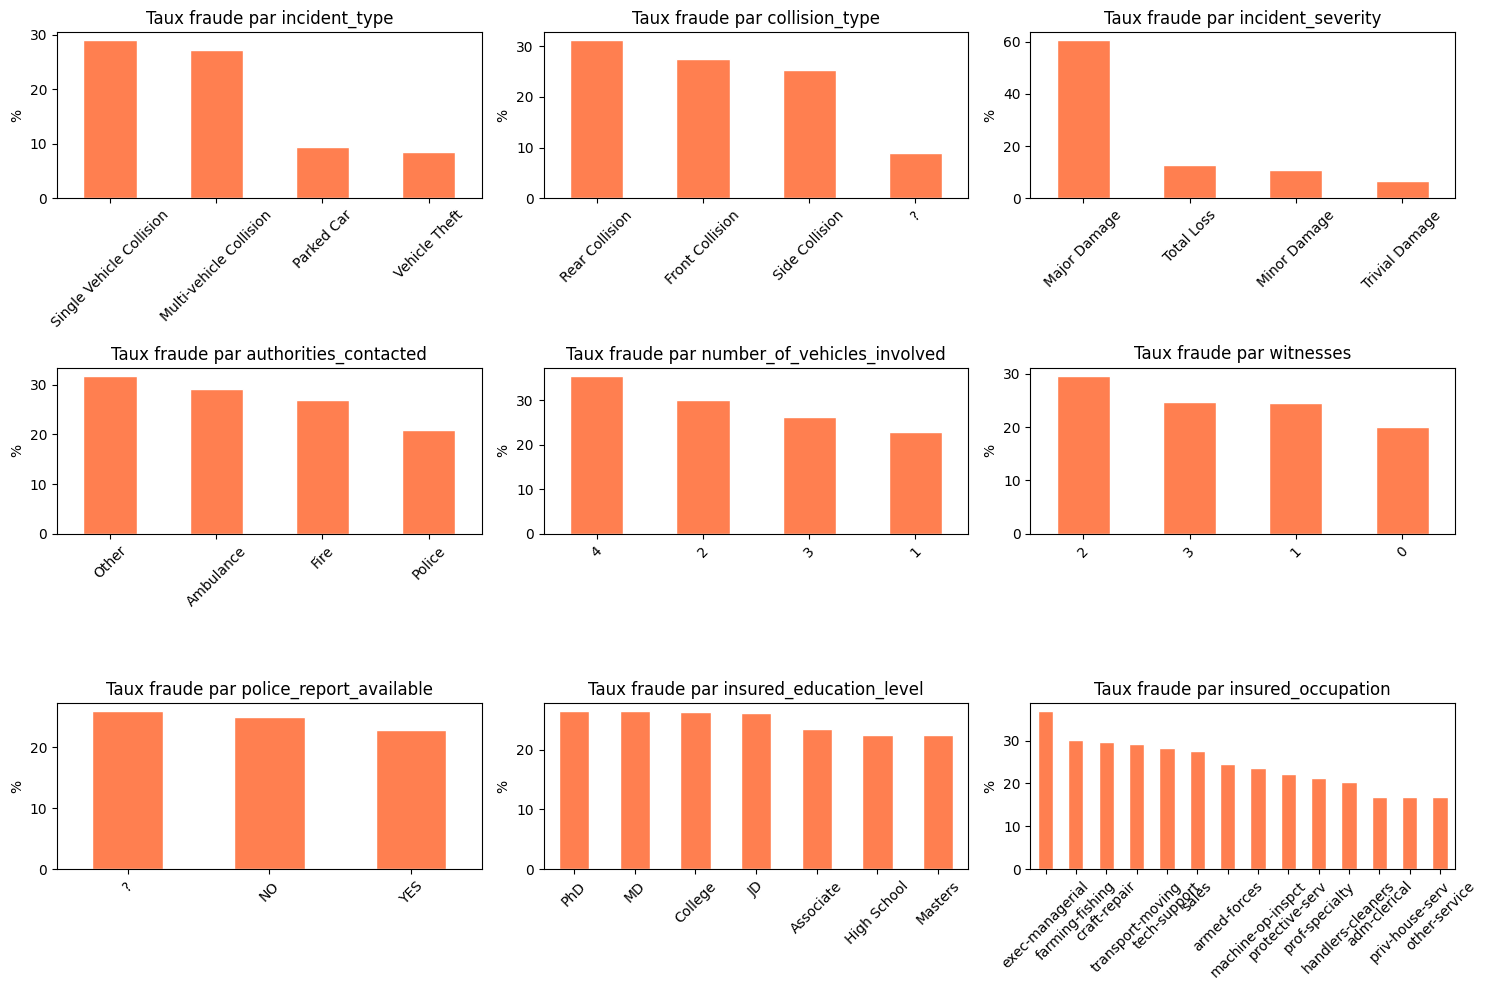

In [7]:
# Taux de fraude par variable catégorielle clé
fraud_binary = (df['fraud_reported'] == 'Y').astype(int)

cat_cols_to_check = [
    'incident_type', 'collision_type', 'incident_severity',
    'authorities_contacted', 'number_of_vehicles_involved',
    'witnesses', 'police_report_available', 'insured_education_level',
    'insured_occupation'
]

# Garder seulement les colonnes présentes dans le dataset
cat_cols_to_check = [c for c in cat_cols_to_check if c in df.columns]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols_to_check[:9]):
    fraud_rate = df.groupby(col)['fraud_reported'].apply(
        lambda x: (x == 'Y').mean() * 100
    ).sort_values(ascending=False)
    fraud_rate.plot(kind='bar', ax=axes[i], color='coral', edgecolor='white')
    axes[i].set_title(f'Taux fraude par {col}')
    axes[i].set_ylabel('%')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [8]:
# Distribution des variables numériques par statut fraude
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['fraud_reported', 'policy_number']]

print("Variables numériques disponibles :")
print(num_cols)

# Top features : comparaison des moyennes fraude vs non-fraude
df['is_fraud'] = (df['fraud_reported'] == 'Y').astype(int)
num_comparison = df.groupby('is_fraud')[num_cols].mean().T
num_comparison.columns = ['Non-fraude', 'Fraude']
num_comparison['ratio'] = (num_comparison['Fraude'] / num_comparison['Non-fraude']).round(2)
num_comparison = num_comparison.sort_values('ratio', ascending=False)
print("\nRatio moyen Fraude / Non-fraude par variable numérique :")
print(num_comparison.round(3))

Variables numériques disponibles :
['months_as_customer', 'age', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'capital-gains', 'capital-loss', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'bodily_injuries', 'witnesses', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'auto_year', '_c39']

Ratio moyen Fraude / Non-fraude par variable numérique :
                              Non-fraude       Fraude  ratio
umbrella_limit               1023904.382  1336032.389   1.30
property_claim                  7018.884     8560.121   1.22
vehicle_claim                  36090.491    43533.644   1.21
total_claim_amount             50288.606    60302.105   1.20
injury_claim                    7179.230     8208.340   1.14
witnesses                          1.456        1.583   1.09
bodily_injuries                    0.976        1.040   1.07
number_of_vehicles_involved        1.809        1.931   1.07
capital-loss                  -

## Bloc 3 — Preprocessing

Règles actuarielles :
- On ne supprime pas de features sans raison — même une feature faiblement
  discriminante peut avoir un effet d'interaction avec d'autres
- On encode les catégorielles par LabelEncoder (XGBoost le gère bien)
- On note les colonnes utilisées pour le déploiement (éviter l'erreur du Module 1
  avec les bins corrigés au notebook 03)

In [9]:
df_proc = df.copy()

# ── 1. Supprimer colonnes non utilisables
# _c39 est souvent une colonne vide/artefact dans ce dataset
drop_cols = ['policy_number', 'policy_bind_date', 'incident_date',
             'insured_zip', '_c39']
drop_cols = [c for c in drop_cols if c in df_proc.columns]
df_proc = df_proc.drop(columns=drop_cols)

print(f"Colonnes après nettoyage : {df_proc.shape[1]}")

# ── 2. Valeurs manquantes
missing = df_proc.isnull().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    print("\nValeurs manquantes :")
    print(missing)
else:
    print("\nAucune valeur manquante.")

# Remplacer '?' par NaN puis imputer par la modalité
df_proc = df_proc.replace('?', np.nan)
for col in df_proc.select_dtypes(include='object').columns:
    mode_val = df_proc[col].mode()
    if len(mode_val) > 0:
        df_proc[col] = df_proc[col].fillna(mode_val[0])
for col in df_proc.select_dtypes(include=np.number).columns:
    df_proc[col] = df_proc[col].fillna(df_proc[col].median())

print(f"Valeurs manquantes après imputation : {df_proc.isnull().sum().sum()}")

Colonnes après nettoyage : 36

Valeurs manquantes :
authorities_contacted    91
dtype: int64
Valeurs manquantes après imputation : 0


In [10]:
# ── 3. Encodage des variables catégorielles
target = 'fraud_reported'
y = (df_proc[target] == 'Y').astype(int)
df_proc = df_proc.drop(columns=[target, 'is_fraud'])

cat_cols = df_proc.select_dtypes(include='object').columns.tolist()
print(f"Colonnes catégorielles à encoder ({len(cat_cols)}) : {cat_cols}")

label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_proc[col] = le.fit_transform(df_proc[col].astype(str))
    label_encoders[col] = le

feature_columns = df_proc.columns.tolist()
X = df_proc.copy()

print(f"\nFeatures finales : {len(feature_columns)}")
print(f"Classe 0 (non-fraude) : {(y==0).sum()} | Classe 1 (fraude) : {(y==1).sum()}")
print(f"Ratio déséquilibre : {(y==0).sum()/(y==1).sum():.1f}:1")

Colonnes catégorielles à encoder (18) : ['policy_state', 'policy_csl', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'insured_relationship', 'incident_type', 'collision_type', 'incident_severity', 'authorities_contacted', 'incident_state', 'incident_city', 'incident_location', 'property_damage', 'police_report_available', 'auto_make', 'auto_model']

Features finales : 34
Classe 0 (non-fraude) : 753 | Classe 1 (fraude) : 247
Ratio déséquilibre : 3.0:1


In [11]:
# ── 4. Split train/test stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train : {len(X_train)} | Test : {len(X_test)}")
print(f"Taux fraude train : {y_train.mean():.1%} | test : {y_test.mean():.1%}")

Train : 800 | Test : 200
Taux fraude train : 24.8% | test : 24.5%


## Bloc 4 — Isolation Forest (non supervisé)

L'Isolation Forest ne voit pas les labels — il apprend la structure "normale"
des sinistres et isole les observations anomales. C'est la technique de choix
quand on n'a pas de données labellisées en production.

In [12]:
# Entraînement sur X_train uniquement (sans y)
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=y_train.mean(),  # proportion attendue de fraude
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train)

# Score d'anomalie : plus négatif = plus anormal
iso_scores_test = iso_forest.decision_function(X_test)
# Normaliser en score 0-100 (100 = très suspect)
iso_scores_normalized = 100 * (1 - (iso_scores_test - iso_scores_test.min()) /
                                   (iso_scores_test.max() - iso_scores_test.min()))

# AUC-ROC de l'Isolation Forest
auc_iso = roc_auc_score(y_test, -iso_scores_test)
print(f"AUC-ROC Isolation Forest : {auc_iso:.4f}")
print("(Référence : 0.5 = aléatoire, 1.0 = parfait)")
print("Attendu pour un IF non supervisé sur fraude assurance : 0.55-0.70")

AUC-ROC Isolation Forest : 0.4787
(Référence : 0.5 = aléatoire, 1.0 = parfait)
Attendu pour un IF non supervisé sur fraude assurance : 0.55-0.70


## Bloc 5 — XGBoost supervisé avec SMOTE

SMOTE (Synthetic Minority Over-sampling Technique) génère des exemples
synthétiques de la classe minoritaire (fraude) pour rééquilibrer le dataset
d'entraînement. On l'applique **uniquement sur le train**, jamais sur le test.

In [13]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Avant SMOTE : {y_train.value_counts().to_dict()}")
print(f"Après SMOTE : {pd.Series(y_train_resampled).value_counts().to_dict()}")

Avant SMOTE : {0: 602, 1: 198}
Après SMOTE : {0: 602, 1: 602}


In [14]:
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_resampled, y_train_resampled,
    eval_set=[(X_test, y_test)],
    verbose=50
)

# Probabilités de fraude sur le test
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

auc_xgb = roc_auc_score(y_test, y_prob_xgb)
print(f"\nAUC-ROC XGBoost : {auc_xgb:.4f}")

[0]	validation_0-auc:0.56731
[50]	validation_0-auc:0.85187
[100]	validation_0-auc:0.83295
[150]	validation_0-auc:0.82214
[200]	validation_0-auc:0.81781
[250]	validation_0-auc:0.81619
[300]	validation_0-auc:0.81376
[350]	validation_0-auc:0.81403
[400]	validation_0-auc:0.81335
[450]	validation_0-auc:0.81673
[499]	validation_0-auc:0.81727

AUC-ROC XGBoost : 0.8173


RAPPORT DE CLASSIFICATION — XGBoost
              precision    recall  f1-score   support

  Non-fraude       0.87      0.87      0.87       151
      Fraude       0.59      0.59      0.59        49

    accuracy                           0.80       200
   macro avg       0.73      0.73      0.73       200
weighted avg       0.80      0.80      0.80       200



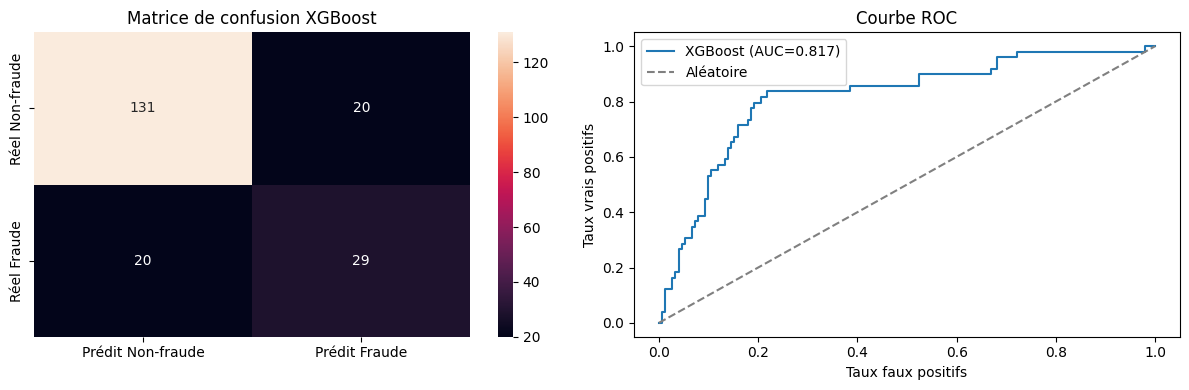

In [15]:
print("=" * 50)
print("RAPPORT DE CLASSIFICATION — XGBoost")
print("=" * 50)
print(classification_report(y_test, y_pred_xgb, target_names=['Non-fraude', 'Fraude']))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_xgb)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm, annot=True, fmt='d', ax=axes[0],
            xticklabels=['Prédit Non-fraude', 'Prédit Fraude'],
            yticklabels=['Réel Non-fraude', 'Réel Fraude'])
axes[0].set_title('Matrice de confusion XGBoost')

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_prob_xgb)
axes[1].plot(fpr, tpr, label=f'XGBoost (AUC={auc_xgb:.3f})')
axes[1].plot([0,1],[0,1],'--', color='gray', label='Aléatoire')
axes[1].set_xlabel('Taux faux positifs')
axes[1].set_ylabel('Taux vrais positifs')
axes[1].set_title('Courbe ROC')
axes[1].legend()

plt.tight_layout()
plt.show()

## Bloc 6 — Choix du seuil optimal

En fraude, le seuil 0.5 par défaut n'est pas optimal. On préfère maximiser
le **rappel** (ne pas rater de fraude) au détriment de la précision (quelques
faux positifs investigués inutilement). On cherche le seuil qui maximise le
F-beta score avec beta=2 (2× plus de poids sur le rappel que la précision).

Seuil optimal (F-beta, beta=2) : 0.147

Avec seuil 0.15 :
              precision    recall  f1-score   support

  Non-fraude       0.94      0.78      0.85       151
      Fraude       0.55      0.84      0.67        49

    accuracy                           0.80       200
   macro avg       0.75      0.81      0.76       200
weighted avg       0.84      0.80      0.81       200



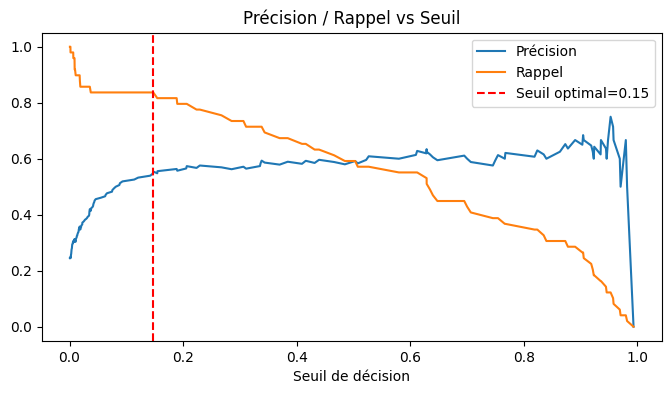

In [16]:
from sklearn.metrics import fbeta_score

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_xgb)

# F-beta (beta=2 : rappel 2x plus important que précision)
beta = 2
fbeta_scores = [
    fbeta_score(y_test, (y_prob_xgb >= t).astype(int), beta=beta, zero_division=0)
    for t in thresholds
]

optimal_threshold = thresholds[np.argmax(fbeta_scores)]
print(f"Seuil optimal (F-beta, beta={beta}) : {optimal_threshold:.3f}")

y_pred_optimal = (y_prob_xgb >= optimal_threshold).astype(int)
print(f"\nAvec seuil {optimal_threshold:.2f} :")
print(classification_report(y_test, y_pred_optimal, target_names=['Non-fraude', 'Fraude']))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], label='Précision')
plt.plot(thresholds, recalls[:-1], label='Rappel')
plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Seuil optimal={optimal_threshold:.2f}')
plt.xlabel('Seuil de décision')
plt.title('Précision / Rappel vs Seuil')
plt.legend()
plt.show()

## Bloc 7 — Score de fraude 0-100 (combinaison IF + XGBoost)

Le score final combine les deux modèles :
- 30% Isolation Forest (signal non supervisé)
- 70% XGBoost supervisé (plus précis, poids plus fort)

Ce score 0-100 est ce que l'API retournera, avec une classification :
- 0-30 : Low Risk (vert)
- 30-60 : Medium Risk (orange)
- 60-80 : High Risk (rouge)
- 80-100 : Very High Risk (rouge foncé, alerte immédiate)

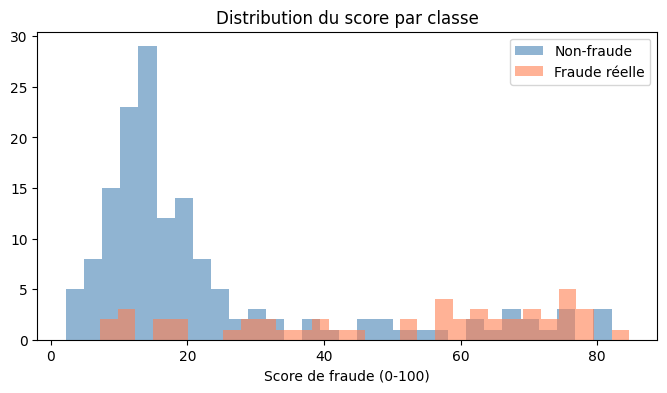

AUC-ROC du score combiné : 0.8085
AUC-ROC XGBoost seul     : 0.8173
AUC-ROC Isolation Forest : 0.4787

Distribution des niveaux de risque :
Low          135
High          34
Medium        28
Very High      3
Name: count, dtype: int64


In [17]:
# Score combiné sur le test
WEIGHT_ISO = 0.30
WEIGHT_XGB = 0.70

iso_score_test = iso_scores_normalized  # déjà calculé en Bloc 4
xgb_score_test = y_prob_xgb * 100       # probabilité → score 0-100

fraud_score = WEIGHT_ISO * iso_score_test + WEIGHT_XGB * xgb_score_test
fraud_score = np.clip(fraud_score, 0, 100)

def classify_risk(score):
    if score < 30:  return 'Low'
    elif score < 60: return 'Medium'
    elif score < 80: return 'High'
    else:            return 'Very High'

risk_levels = [classify_risk(s) for s in fraud_score]

# Distribution du score
plt.figure(figsize=(8, 4))
plt.hist(fraud_score[y_test==0], bins=30, alpha=0.6, label='Non-fraude', color='steelblue')
plt.hist(fraud_score[y_test==1], bins=30, alpha=0.6, label='Fraude réelle', color='coral')
plt.xlabel('Score de fraude (0-100)')
plt.title('Distribution du score par classe')
plt.legend()
plt.show()

# AUC du score combiné
auc_combined = roc_auc_score(y_test, fraud_score)
print(f"AUC-ROC du score combiné : {auc_combined:.4f}")
print(f"AUC-ROC XGBoost seul     : {auc_xgb:.4f}")
print(f"AUC-ROC Isolation Forest : {auc_iso:.4f}")

# Distribution des niveaux de risque
print("\nDistribution des niveaux de risque :")
print(pd.Series(risk_levels).value_counts())

## Bloc 8 — Feature Importance (SHAP)

SHAP (SHapley Additive exPlanations) donne une interprétation locale et globale
du modèle. C'est indispensable pour l'actuariat : l'équipe fraude veut savoir
*pourquoi* un sinistre est suspect, pas juste *combien* il l'est.

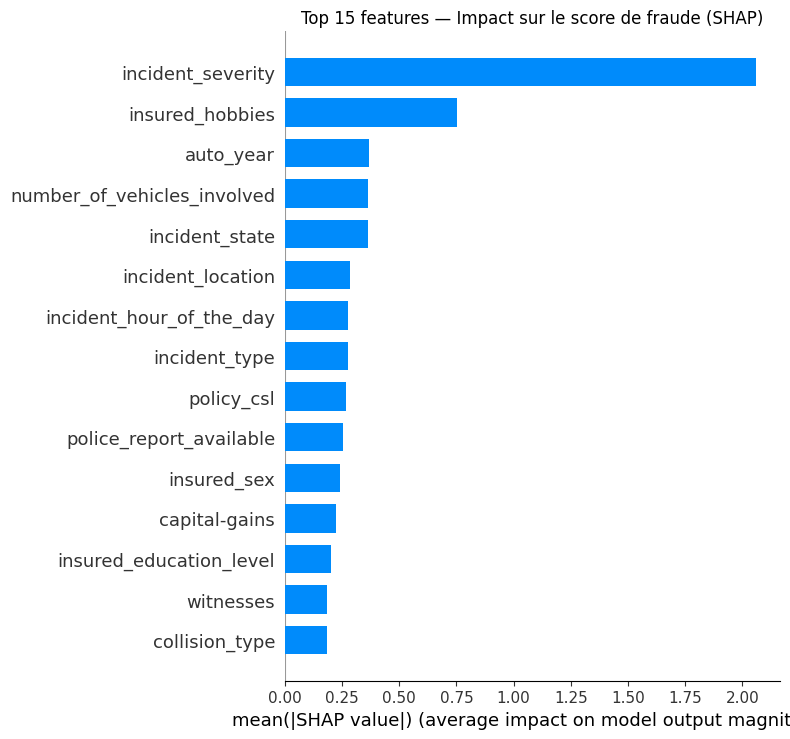

Top 10 features pour la détection de fraude :
                        feature  importance
16            incident_severity    2.061211
10              insured_hobbies    0.751691
33                    auto_year    0.369850
22  number_of_vehicles_involved    0.362680
18               incident_state    0.361813
20            incident_location    0.283151
21     incident_hour_of_the_day    0.277022
14                incident_type    0.274080
3                    policy_csl    0.268750
26      police_report_available    0.253306


In [18]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type='bar',
                  feature_names=feature_columns,
                  max_display=15, show=False)
plt.title('Top 15 features — Impact sur le score de fraude (SHAP)')
plt.tight_layout()
plt.show()

# Top 5 features les plus importantes
shap_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': np.abs(shap_values).mean(axis=0)
}).sort_values('importance', ascending=False)

print("Top 10 features pour la détection de fraude :")
print(shap_importance.head(10))

## Bloc 9 — Checklist de validation

Avant d'intégrer dans FastAPI, vérifier :

- [ ] AUC-ROC XGBoost > 0.75 (cible raisonnable sur ce dataset)
- [ ] Rappel (fraude) > 0.70 avec le seuil optimal (on ne rate pas trop de fraudes)
- [ ] Distribution du score : fraudes concentrées > 60, non-fraudes < 40
- [ ] AUC du score combiné ≥ AUC XGBoost seul (l'Isolation Forest apporte quelque chose)
- [ ] SHAP : les top features ont un sens métier (pas de feature aléatoire en top 3)

In [21]:
print("=" * 50)
print("VALIDATION ACTUARIELLE — Module 2")
print("=" * 50)

from sklearn.metrics import recall_score, precision_score

recall_optimal = recall_score(y_test, y_pred_optimal)
precision_optimal = precision_score(y_test, y_pred_optimal)

checks = {
    'AUC XGBoost > 0.75': auc_xgb > 0.75,
    'Rappel fraude > 0.70': recall_optimal > 0.70,
    'Score combiné ≥ XGBoost': auc_combined >= auc_xgb - 0.005,  # tolérance 0.5%
}

for check, result in checks.items():
    status = 'ok' if result else 'no'
    print(f"{status} {check}")

print(f"\nAUC-ROC XGBoost    : {auc_xgb:.4f}")
print(f"AUC-ROC Combiné    : {auc_combined:.4f}")
print(f"Rappel fraude      : {recall_optimal:.2%}")
print(f"Précision fraude   : {precision_optimal:.2%}")
print(f"Seuil optimal      : {optimal_threshold:.3f}")

VALIDATION ACTUARIELLE — Module 2
ok AUC XGBoost > 0.75
ok Rappel fraude > 0.70
no Score combiné ≥ XGBoost

AUC-ROC XGBoost    : 0.8173
AUC-ROC Combiné    : 0.8085
Rappel fraude      : 83.67%
Précision fraude   : 55.41%
Seuil optimal      : 0.147


## Bloc 10 — Export pour FastAPI

In [22]:
import os
os.makedirs('fraud_artifacts', exist_ok=True)

# 1. Modèles
joblib.dump(xgb_model, 'fraud_artifacts/xgb_fraud.pkl')
joblib.dump(iso_forest, 'fraud_artifacts/iso_forest_fraud.pkl')

# 2. Encodeurs (nécessaires pour transformer les inputs en production)
joblib.dump(label_encoders, 'fraud_artifacts/label_encoders.pkl')

# 3. Métadonnées de déploiement
fraud_meta = {
    'feature_columns': feature_columns,
    'categorical_columns': cat_cols,
    'target_column': 'fraud_reported',
    'optimal_threshold': float(optimal_threshold),
    'weight_isolation_forest': WEIGHT_ISO,
    'weight_xgboost': WEIGHT_XGB,
    'risk_thresholds': {
        'Low': [0, 30],
        'Medium': [30, 60],
        'High': [60, 80],
        'Very High': [80, 100]
    },
    'performance': {
        'auc_roc_xgb': float(auc_xgb),
        'auc_roc_iso': float(auc_iso),
        'auc_roc_combined': float(auc_combined),
        'recall_fraud_optimal': float(recall_optimal),
        'precision_fraud_optimal': float(precision_optimal),
    },
    'top_features': shap_importance.head(10)[['feature', 'importance']].to_dict(orient='records'),
    'contamination_rate': float(y_train.mean()),
    'n_train': len(X_train),
    'n_test': len(X_test),
}

with open('fraud_artifacts/fraud_meta.json', 'w') as f:
    json.dump(fraud_meta, f, indent=2)

print("Artifacts exportés dans fraud_artifacts/ :")
for f in os.listdir('fraud_artifacts'):
    size = os.path.getsize(f'fraud_artifacts/{f}')
    print(f"  {f} ({size/1024:.1f} KB)")

print("\nExport terminé. Copier fraud_artifacts/ dans siap-backend/app/ml_models/fraud/")

Artifacts exportés dans fraud_artifacts/ :
  xgb_fraud.pkl (866.7 KB)
  label_encoders.pkl (23.0 KB)
  fraud_meta.json (2.8 KB)
  iso_forest_fraud.pkl (3941.8 KB)

Export terminé. Copier fraud_artifacts/ dans siap-backend/app/ml_models/fraud/


In [23]:
# Score de production = XGBoost uniquement
WEIGHT_ISO = 0.0
WEIGHT_XGB = 1.0

# Régénère le JSON et les artifacts avec ces poids corrects
fraud_meta['weight_isolation_forest'] = WEIGHT_ISO
fraud_meta['weight_xgboost'] = WEIGHT_XGB
fraud_meta['performance']['auc_roc_combined'] = float(auc_xgb)  # = XGB seul

with open('fraud_artifacts/fraud_meta.json', 'w') as f:
    json.dump(fraud_meta, f, indent=2)

print("fraud_meta.json mis à jour.")

fraud_meta.json mis à jour.


In [24]:
# Télécharger tous les artifacts d'un coup (zip)
import shutil
from google.colab import files

shutil.make_archive('fraud_artifacts', 'zip', 'fraud_artifacts')
files.download('fraud_artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>